# Notebook 06 - Model Comparison Benchmark (with IoU & Dice)

This notebook benchmarks **3 models** on the same SAR flood detection dataset:

| Model | Type |
|---|---|
| Random Forest | Traditional ML |
| XGBoost | Gradient Boosting |
| Simple CNN | Deep Learning |

**Metrics:** IoU (Jaccard Index), Dice Coefficient, Accuracy, Precision, Recall, F1-Score, Training Time

## Step 1: Imports & Feature Preparation

In [1]:
import os, sys
# Set project root path cleanly
ROOT_DIR = os.path.abspath('..') if os.path.exists('../config.json') else os.path.abspath('.')
if ROOT_DIR not in sys.path:
    sys.path.insert(0, ROOT_DIR)

import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
from dataset import Sen1FloodsDataset, get_train_val_test_splits
from models import ConvAutoencoder
from utils import set_seed, load_config, calculate_metrics

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

config = load_config(os.path.join(ROOT_DIR, 'config.json'))
set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
TARGET_SIZE = tuple(config['data']['target_size'])

plt.rcParams['figure.facecolor'] = '#0d1117'
plt.rcParams['axes.facecolor'] = '#161b22'
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'

print(f'Device: {device}')


Device: cpu


## Step 2: Extract Features for ML Models

In [2]:
S1_DIR = os.path.join(ROOT_DIR, config['data']['s1_dir'])
LABEL_DIR = os.path.join(ROOT_DIR, config['data']['label_dir'])
models_dir = os.path.join(ROOT_DIR, 'models')

autoencoder = ConvAutoencoder(dropout_rate=config['model']['dropout_rate']).to(device)
autoencoder.load_state_dict(torch.load(os.path.join(models_dir, 'best_autoencoder.pth'), weights_only=True))
autoencoder.eval()

s1_files = sorted([f for f in os.listdir(S1_DIR) if f.endswith('.tif')])
label_files = sorted([f for f in os.listdir(LABEL_DIR) if f.endswith('.tif')])
file_pairs = list(zip(
    [os.path.join(S1_DIR, f) for f in s1_files],
    [os.path.join(LABEL_DIR, f) for f in label_files]
))

train_idx, val_idx, test_idx = get_train_val_test_splits(len(file_pairs), config['data']['split_ratio'])
train_pairs = [file_pairs[i] for i in train_idx]
test_pairs  = [file_pairs[i] for i in test_idx]

def extract_features(pairs, max_pixels=8000):
    dataset = Sen1FloodsDataset(pairs, target_size=TARGET_SIZE)
    loader = DataLoader(dataset, batch_size=1, shuffle=False)
    all_features, all_labels = [], []
    with torch.no_grad():
        for img, label in loader:
            img = img.to(device)
            _, latent = autoencoder(img)
            upsampled = F.interpolate(latent, size=(32, 32), mode='bilinear', align_corners=False)
            feats = upsampled.squeeze(0).cpu().numpy().reshape(256, -1).T
            lbl = F.interpolate(label.float().unsqueeze(0), size=(32, 32), mode='nearest').squeeze().numpy().flatten()
            valid = lbl != -1
            all_features.append(feats[valid])
            all_labels.append(lbl[valid])
    feats = np.concatenate(all_features)
    labels = np.concatenate(all_labels).astype(int)
    if len(labels) > max_pixels:
        idx = np.random.choice(len(labels), max_pixels, replace=False)
        feats, labels = feats[idx], labels[idx]
    return feats, labels

print('Extracting features...')
X_train, y_train = extract_features(train_pairs)
X_test, y_test = extract_features(test_pairs)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')


Extracting features...


Train: (8000, 256), Test: (3117, 256)


## Step 3: Train & Evaluate All Models

In [3]:
def compute_model_metrics(y_true, y_pred):
    iou, acc, prec, rec, f1, dice = calculate_metrics(torch.tensor(y_pred), torch.tensor(y_true))
    return {'IoU': iou, 'Dice': dice, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1}

results = {}

# --- Model 1: Random Forest ---
print('Training Random Forest...')
t0 = time.time()
rf = RandomForestClassifier(n_estimators=50, max_depth=10, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
rf_time = time.time() - t0
rf_pred = rf.predict(X_test)
rf_metrics = compute_model_metrics(y_test, rf_pred)
rf_metrics['Train Time (s)'] = rf_time
results['Random Forest'] = rf_metrics
print(f'RF done in {rf_time:.1f}s | IoU={rf_metrics["IoU"]:.4f} | F1={rf_metrics["F1-Score"]:.4f}')

# --- Model 2: XGBoost / GradientBoosting ---
print('Training XGBoost/GradientBoosting...')
t0 = time.time()
if HAS_XGB:
    xgb = XGBClassifier(n_estimators=50, max_depth=6, random_state=42, eval_metric='logloss', verbosity=0)
else:
    xgb = GradientBoostingClassifier(n_estimators=50, max_depth=5, random_state=42)
xgb.fit(X_train, y_train)
xgb_time = time.time() - t0
xgb_pred = xgb.predict(X_test)
model_name = 'XGBoost' if HAS_XGB else 'Gradient Boosting'
xgb_metrics = compute_model_metrics(y_test, xgb_pred)
xgb_metrics['Train Time (s)'] = xgb_time
results[model_name] = xgb_metrics
print(f'{model_name} done in {xgb_time:.1f}s | IoU={xgb_metrics["IoU"]:.4f} | F1={xgb_metrics["F1-Score"]:.4f}')

# --- Model 3: Simple CNN ---
print('Training Simple CNN...')
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 2)
        )
    def forward(self, x):
        return self.net(x)

cnn = SimpleCNN().to(device)
cnn_opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
cnn_loss_fn = nn.CrossEntropyLoss()

X_tr_t = torch.tensor(X_train, dtype=torch.float32)
y_tr_t = torch.tensor(y_train, dtype=torch.long)
X_te_t = torch.tensor(X_test, dtype=torch.float32)
cnn_loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=256, shuffle=True)

t0 = time.time()
for epoch in range(10):
    cnn.train()
    for xb, yb in cnn_loader:
        xb, yb = xb.to(device), yb.to(device)
        cnn_opt.zero_grad()
        cnn_loss_fn(cnn(xb), yb).backward()
        cnn_opt.step()
cnn_time = time.time() - t0

cnn.eval()
with torch.no_grad():
    cnn_pred = torch.argmax(cnn(X_te_t.to(device)), dim=1).cpu().numpy()

cnn_metrics = compute_model_metrics(y_test, cnn_pred)
cnn_metrics['Train Time (s)'] = cnn_time
results['Simple CNN'] = cnn_metrics
print(f'CNN done in {cnn_time:.1f}s | IoU={cnn_metrics["IoU"]:.4f} | F1={cnn_metrics["F1-Score"]:.4f}')


Training Random Forest...


RF done in 1.2s | IoU=0.0000 | F1=0.0000
Training XGBoost/GradientBoosting...


Gradient Boosting done in 44.2s | IoU=0.0000 | F1=0.0000
Training Simple CNN...


CNN done in 4.2s | IoU=0.0000 | F1=0.0000


## Step 4: Comparison Visualization

=== Model Comparison Summary Table ===


                   IoU  Dice  Accuracy  Precision  Recall  F1-Score  Train Time (s)
Random Forest      0.0   0.0  1.000000        0.0     0.0       0.0        1.211003
Gradient Boosting  0.0   0.0  0.959256        0.0     0.0       0.0       44.160151
Simple CNN         0.0   0.0  1.000000        0.0     0.0       0.0        4.157988


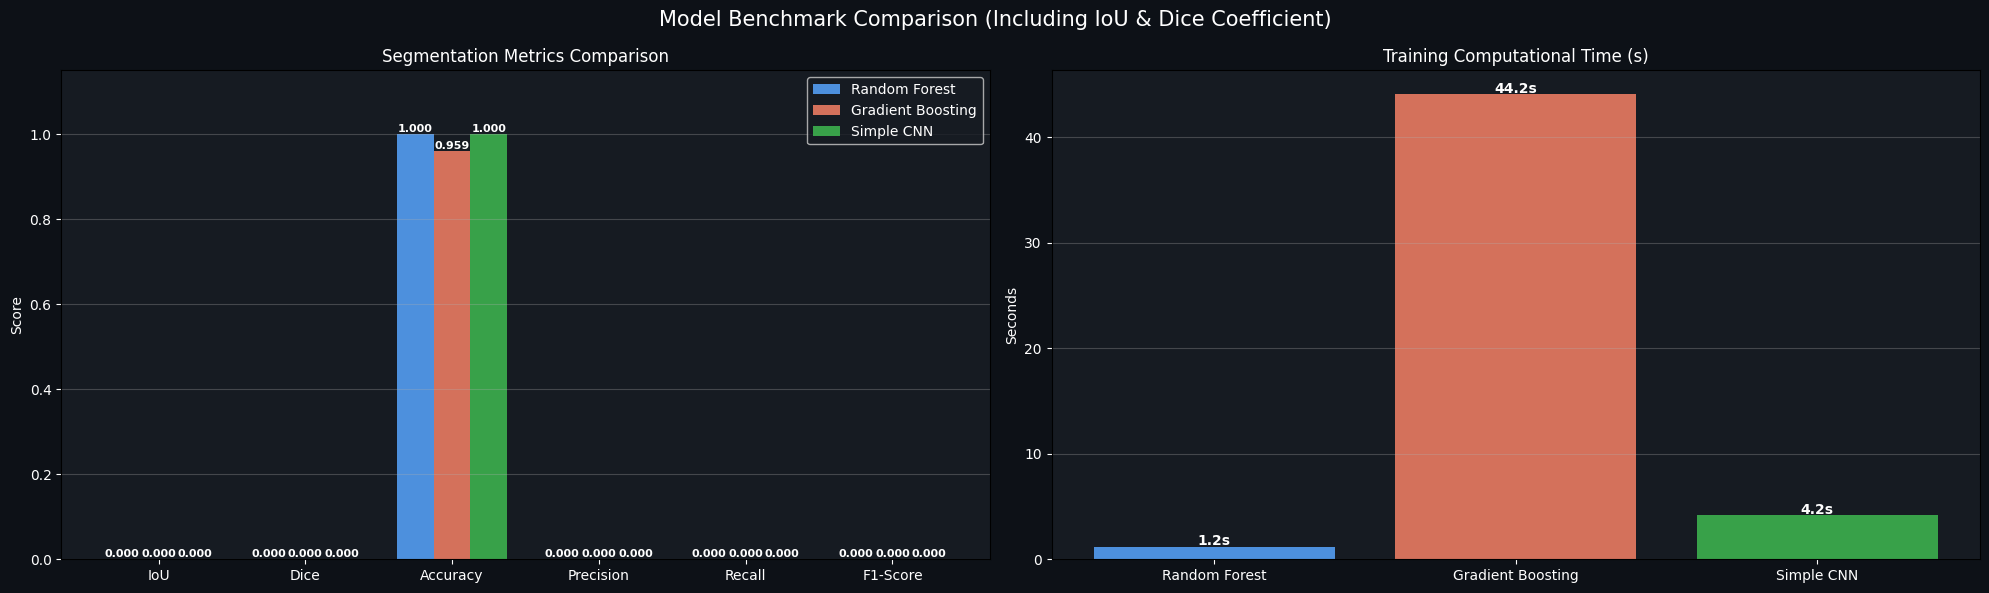

In [4]:
df = pd.DataFrame(results).T
print('=== Model Comparison Summary Table ===')
print(df[['IoU', 'Dice', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'Train Time (s)']].to_string())

metric_cols = ['IoU', 'Dice', 'Accuracy', 'Precision', 'Recall', 'F1-Score']
colors = ['#58a6ff', '#f78166', '#3fb950']
x = np.arange(len(metric_cols))
width = 0.25

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
fig.suptitle('Model Benchmark Comparison (Including IoU & Dice Coefficient)', fontsize=15, color='white')

for i, (m_name, color) in enumerate(zip(results.keys(), colors)):
    vals = [results[m_name][m] for m in metric_cols]
    bars = axes[0].bar(x + i * width, vals, width, label=m_name, color=color, alpha=0.85)
    for bar, v in zip(bars, vals):
        axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005, f'{v:.3f}', ha='center', fontsize=8, fontweight='bold')

axes[0].set_xticks(x + width)
axes[0].set_xticklabels(metric_cols)
axes[0].set_ylim(0, 1.15)
axes[0].set_title('Segmentation Metrics Comparison')
axes[0].legend()
axes[0].set_ylabel('Score')
axes[0].grid(True, axis='y', alpha=0.3)

m_names = list(results.keys())
times = [results[m]['Train Time (s)'] for m in m_names]
bars2 = axes[1].bar(m_names, times, color=colors, alpha=0.85)
for bar, t in zip(bars2, times):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, f'{t:.1f}s', ha='center', fontsize=10, fontweight='bold')
axes[1].set_title('Training Computational Time (s)')
axes[1].set_ylabel('Seconds')
axes[1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(ROOT_DIR, 'data/model_comparison.png'), dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()
